# News Topic Classification

Classifies HuffPost news headlines from the News Category Dataset into 3 topics (**SPORTS**, **TECH** and **BUSINESS**, ~13,000 headlines) with TF-IDF features, and compares Logistic Regression, Random Forest and K-Nearest Neighbors.

**Data:** `News_Category_Dataset_v3.json` (see [`../data/README.md`](../data/README.md)).

In [ ]:
# Import the libraries
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
import pickle
import matplotlib.pyplot as plt

DATA_DIR = "../data/"

In [ ]:
# Load the dataset (`News_Category_Dataset_v3.json`)
df = pd.read_json(DATA_DIR + 'News_Category_Dataset_v3.json', encoding='latin-1', lines = True)

In [ ]:
df

,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22
...,...,...,...,...,...,...
209522,https://www.huffingtonpost.com/entry/rim-ceo-t...,RIM CEO Thorsten Heins' 'Significant' Plans Fo...,TECH,Verizon Wireless and AT&T are already promotin...,"Reuters, Reuters",2012-01-28
209523,https://www.huffingtonpost.com/entry/maria-sha...,Maria Sharapova Stunned By Victoria Azarenka I...,SPORTS,"Afterward, Azarenka, more effusive with the pr...",,2012-01-28
209524,https://www.huffingtonpost.com/entry/super-bow...,"Giants Over Patriots, Jets Over Colts Among M...",SPORTS,"Leading up to Super Bowl XLVI, the most talked...",,2012-01-28
209525,https://www.huffingtonpost.com/entry/aldon-smi...,Aldon Smith Arrested: 49ers Linebacker Busted ...,SPORTS,CORRECTION: An earlier version of this story i...,,2012-01-28


In [ ]:
# Keep the headline and category, and only 3 categories
df = df[['headline', 'category']]
df = df[df['category'].isin(['SPORTS', 'TECH', 'BUSINESS'])]

In [ ]:
df.tail(50)

,headline,category
208816,"China's Premier, Wen Jiabao, Stresses Importan...",BUSINESS
208817,Fannie Mae Ignored Crucial Warnings Of Mortgag...,BUSINESS
208818,Influencer of the Week: Cancer-Conquering Supe...,BUSINESS
208822,Facebook Birthday: Social Network Turns 8,TECH
208823,"New Apple Rumors: iPad 3 In March, iPhone 5 In...",TECH
208824,TiVo Shares Get Big Discount As Digital Video ...,TECH
208825,Google Hires A Senior Director At Apple For A ...,TECH
208877,Let Them Eat Task Forces,BUSINESS
208878,"Duncan Niederauer, NYSE CEO: 'Mega-Mergers' Un...",BUSINESS
208879,State Bank Of India To Name And Shame Defaulters,BUSINESS


In [ ]:
# Step 2: Text preprocessing with TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)
X = vectorizer.fit_transform(df['headline'])
y = df['category']

In [ ]:
# Convert the categories to numeric labels
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)

In [ ]:
# Step 3: Split into training and test sets (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# Models to train
modelos = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5)
}

In [ ]:
# Dictionary to store the results
resultados = {'Modelo': [], 'Precisión': [], 'F1-Score': [], 'Recall': [], 'Precision Avg.': []}

# Train and evaluate each model
for nombre, modelo in modelos.items():
    print(f"Evaluando modelo: {nombre}")

    # Train the model
    modelo.fit(X_train, y_train)

    # Predict on the test set
    y_pred = modelo.predict(X_test)

    # Compute the metrics (accuracy is stored as 'Precisión')
    precision = accuracy_score(y_test, y_pred)
    reporte = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

    # Weighted-average metrics
    f1_score = reporte['weighted avg']['f1-score']
    recall = reporte['weighted avg']['recall']
    precision_avg = reporte['weighted avg']['precision']

    # Print the results
    print(f"\nPrecisión de {nombre}: {precision}")
    print("Matriz de Confusión:")
    print(confusion_matrix(y_test, y_pred))
    print("Reporte de Clasificación:")
    print(classification_report(y_test, y_pred))
    print("\n" + "="*60 + "\n")

    # Save the results
    resultados['Modelo'].append(nombre)
    resultados['Precisión'].append(precision)
    resultados['F1-Score'].append(f1_score)
    resultados['Recall'].append(recall)
    resultados['Precision Avg.'].append(precision_avg)

Evaluando modelo: Logistic Regression

Precisión de Logistic Regression: 0.8585526315789473
Matriz de Confusión:
[[1636   79   51]
 [ 137 1415    5]
 [ 254   33  342]]
Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.81      0.93      0.86      1766
           1       0.93      0.91      0.92      1557
           2       0.86      0.54      0.67       629

    accuracy                           0.86      3952
   macro avg       0.86      0.79      0.82      3952
weighted avg       0.86      0.86      0.85      3952



Evaluando modelo: Random Forest

Precisión de Random Forest: 0.8352732793522267
Matriz de Confusión:
[[1583   98   85]
 [ 208 1338   11]
 [ 205   44  380]]
Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.79      0.90      0.84      1766
           1       0.90      0.86      0.88      1557
           2       0.80      0.60      0.69       629

    accuracy           

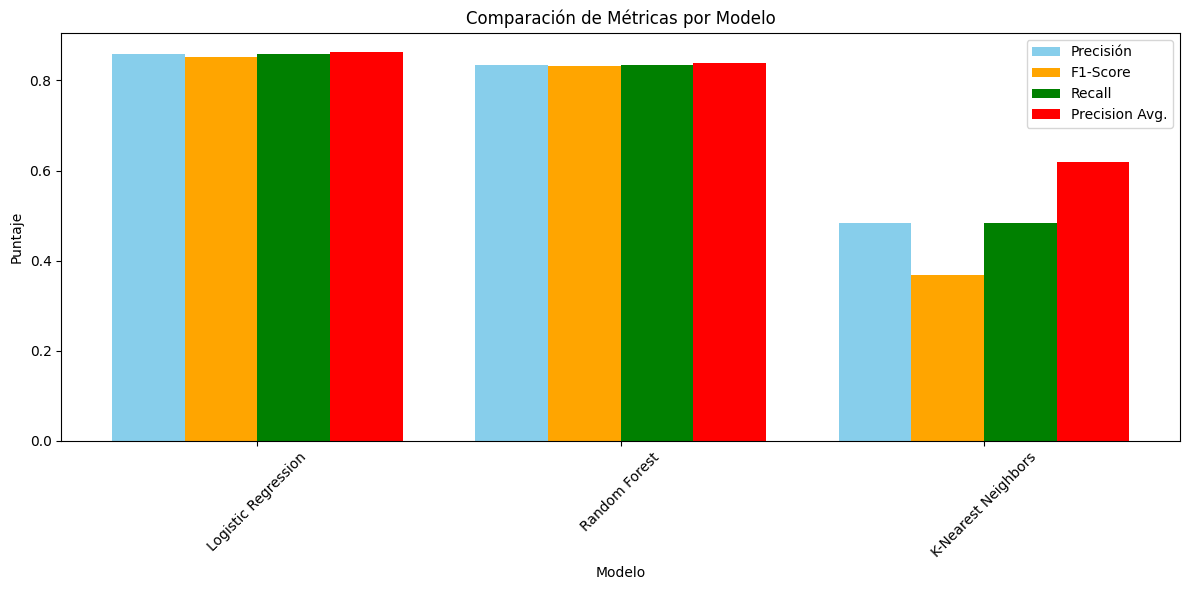

In [ ]:
import numpy as np

# Visualization: bar chart comparing the metrics of each model
resultados_df = pd.DataFrame(resultados)

plt.figure(figsize=(12, 6))
x = np.arange(len(resultados_df['Modelo']))
width = 0.2

# One bar per metric
plt.bar(x - width * 1.5, resultados_df['Precisión'], width, label='Precisión', color='skyblue')
plt.bar(x - width * 0.5, resultados_df['F1-Score'], width, label='F1-Score', color='orange')
plt.bar(x + width * 0.5, resultados_df['Recall'], width, label='Recall', color='green')
plt.bar(x + width * 1.5, resultados_df['Precision Avg.'], width, label='Precision Avg.', color='red')

# Chart settings
plt.xticks(x, resultados_df['Modelo'], rotation=45)
plt.title('Comparación de Métricas por Modelo')
plt.ylabel('Puntaje')
plt.xlabel('Modelo')
plt.legend(loc='best')
plt.tight_layout()

# Show the chart
plt.show()

## Results

| Model | Accuracy | Weighted F1 |
|---|---|---|
| Logistic Regression | **85.9%** | 0.85 |
| Random Forest | 83.5% | 0.83 |
| K-Nearest Neighbors | 48.3% | 0.37 |

Logistic Regression performs best. KNN predicts almost everything as the majority class, which is typical of distance-based models on sparse, high-dimensional TF-IDF vectors.